In [6]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Checking database filtering

In [7]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV results for Martin Kozak
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


In [8]:
data=pd.read_csv("SiComplete-2021-06-28-BiatriSrv-v2.2.1-WithUnfinishedBicolors-WithToleranceOnField-WithAll.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes

##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_au          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


In [9]:
data=datafull
data=data[data.Efield2==0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.000000,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.50,937.147441
6,5026870.0,20180521.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.000000,8.000000e-07,...,0.006720,0.031501,-4.435532e+13,2.365529e+26,7.879395e+39,7.885098e+39,3.0,2.0,3475.00,1350.561171
22,17401928.0,20200105.0,24.0,0.434637,2.200000e-06,2.000000e-14,5.000000e+08,0.000000,0.000000,2.200000e-06,...,0.000011,0.000038,-3.445825e+13,9.840502e+26,5.406782e+36,4.920251e+40,3.0,2.0,4125.00,1130.207409
23,4968648.0,20180516.0,24.0,0.434637,8.000000e-07,2.000000e-14,5.500000e+08,0.000000,0.000000,8.000000e-07,...,0.001328,0.008564,-8.637288e+12,6.532126e+25,3.256158e+39,3.266063e+39,3.0,2.0,3162.50,937.147441
24,5027630.0,20180525.0,24.0,0.434637,4.000000e-07,2.000000e-14,5.000000e+09,0.000000,0.000000,4.000000e-07,...,0.509266,5.411101,-3.107904e+14,2.000978e+28,1.001070e+42,1.000489e+42,3.0,2.0,2400.00,881.987451
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2360,460337.0,20210607.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,0.628319,2.656000e-06,...,0.000000,0.317643,-6.721950e+14,2.499799e+27,1.794610e+41,1.792613e+41,1.0,0.0,3266.25,1153.010893
2361,460330.0,20210606.0,24.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.785398,-0.471239,2.656000e-06,...,0.000000,0.316438,-6.758071e+14,2.507067e+27,1.794057e+41,1.797825e+41,1.0,0.0,3266.25,1153.010893
2362,460361.0,20210613.0,24.0,0.434637,2.656000e-06,1.394500e-14,1.050000e+10,0.785398,1.099557,2.656000e-06,...,0.000000,39.889875,-2.040417e+15,8.658356e+28,6.209462e+42,6.208932e+42,1.0,0.0,3266.25,1153.010893
2363,460345.0,20210609.0,24.0,0.434637,2.656000e-06,1.394500e-14,1.050000e+10,0.785398,-1.413717,2.656000e-06,...,0.000000,39.842430,3.083916e+15,8.676632e+28,6.221966e+42,6.222038e+42,1.0,0.0,3266.25,1153.010893


In [10]:
datafull=data
data = data[data.lambda1==2656e-9]
data.tau1*1E15
data[np.abs(data.tau1 - 13.945e-15)/data.tau1 < 0.01]

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2230,441932.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.000000,0.000000,0.000003,...,0.0,78.535969,2.231728e+15,8.493052e+28,6.090377e+42,6.090392e+42,1.0,0.0,3266.25,1153.010893
2231,441931.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.000000,0.000003,...,0.0,0.477183,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2232,449780.0,20210510.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,1.570796,0.000003,...,0.0,0.478813,-2.899690e+14,1.976060e+27,1.418774e+41,1.417039e+41,1.0,0.0,3266.25,1153.010893
2233,449793.0,20210514.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.000000,0.349066,0.000003,...,0.0,78.874475,1.831605e+15,8.506090e+28,6.099051e+42,6.099742e+42,1.0,0.0,3266.25,1153.010893
2234,449791.0,20210512.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.000000,0.448799,0.000003,...,0.0,79.002251,2.120414e+15,8.518570e+28,6.109439e+42,6.108691e+42,1.0,0.0,3266.25,1153.010893
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2360,460337.0,20210607.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.628319,0.000003,...,0.0,0.317643,-6.721950e+14,2.499799e+27,1.794610e+41,1.792613e+41,1.0,0.0,3266.25,1153.010893
2361,460330.0,20210606.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,-0.471239,0.000003,...,0.0,0.316438,-6.758071e+14,2.507067e+27,1.794057e+41,1.797825e+41,1.0,0.0,3266.25,1153.010893
2362,460361.0,20210613.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,1.099557,0.000003,...,0.0,39.889875,-2.040417e+15,8.658356e+28,6.209462e+42,6.208932e+42,1.0,0.0,3266.25,1153.010893
2363,460345.0,20210609.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,-1.413717,0.000003,...,0.0,39.842430,3.083916e+15,8.676632e+28,6.221966e+42,6.222038e+42,1.0,0.0,3266.25,1153.010893


# Generating the HHG spectrum as function of CEP

In [16]:
!$QuantumLaPsources/octopus_slabs/Libs/plotHHGspectra.py

  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ====== PULSE 1 =====
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** Efield1*           size = 2
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** wavelength1*       size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** pulse duration*    size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** CEP1               size = 8
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ====== PULSE 2 =====
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** Efield2*           size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** wavelength2*       size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserParameters - INFO - ** pulse duration*    size = 1
  octopus_slabs.Libs.libPlotting - CountTheNumberOfLaserP

Size of HHG file: 6000
** Info: interpolating...
** Debug: 59.99999994
** Debug: checking length of new mesh: (600,)
59 deg.
octopus-td.449794*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field3E9-CEP0.5-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 90.0
** Debug: checking length of new mesh: (600,)
90 deg.
** Info: Exporting to file HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.csv
** Preparing plot...
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  octopus_slabs.Libs.libPlotting - plot2dHeatMap_HHG - INFO - 4800
  matplotlib.font_manager - _findfont_cached - WARNING - findfont: Font family ['sans-serif'] not found. Falling back to DejaVu Sans.
  matplotlib.font_

Size of HHG file: 6000
** Info: interpolating...
** Debug: 30.0000006
** Debug: checking length of new mesh: (600,)
30 deg.
octopus-td.449804*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.05E10-CEP0.25-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 45.0
** Debug: checking length of new mesh: (600,)
45 deg.
octopus-td.449803*.log
/home/thibault.derrien/Documents/octopus.data/03-Bulk3D/Si-1x1x1-k-24x24x1-Angle0.25-Mesh0.4346370088553005-Mesh0.4346370088553005-T0e0/lambda2656e-9-tau13.945e-15-field1.05E10-CEP0.333333333-theta0.25-SinSquared-SinPower2-2/lambda400e-9-tau30e-15-field0E0-CEP0.0-delay0.5e-15-SinSquared
Size of HHG file: 6000
** Info: interpolating...
** Debug: 59.99999994
** Debug: checking length of new mesh: (600,)
59 deg.
octopus-td.449802*

In [22]:
!ls HHGspectrum*.png

HHGspectrumWithCEP-wavelength2656nm-Efield10500000000.png
HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.png


In [7]:
!display HHGspectrumWithCEP-wavelength2656nm-Efield10500000000.png

display: unable to open X server `localhost:11.0' @ error/display.c/DisplayImageCommand/410.


In [24]:
!display HHGspectrumWithCEP-wavelength2656nm-Efield3000000000.png

^C


# Improving HHG spectra: refining the energy range

In [3]:
from scipy.constants import h, c, e
h*c/e/250E-9

4.959367937328011

Remaining problem is: the energy of the spectrum is far too high. We need to decrease it by a factor of 10. 

For doing so, it is proposed to play with the temporal resolution. Following Heisenberg uncertainty / Noether theorem, we shall simply try to decrease number of samples by 10. Let's see if this brings us more resolution or less. In principle, decreasing time precision should increase energy precision. 

In [9]:
# from scipy.fft import fft, fftfreq, fftshift
from numpy import fft
import numpy as np
from scipy.constants import c, hbar, e
import matplotlib.pyplot as plt

# del t, y
# number of signal points
N = 10_000 #this controls timestep, it does not control time window duration. Then it acts only on the maximum energy one can address in Fourier spectrum

wavelength = 2000e-9; tau=10e-15 #bicolor cycles for excitation rate
#wavelength = 2656e-9; tau=13e-15 #Kozak experimental, pulse rescaled for TDDFT LDA
#wavelength = 3200e-9; tau=30e-15 #Pulse used for orientation-dep excitation rate
omega = 2*np.pi*c/wavelength
T = 2*np.pi/omega
sigma_tau=tau/(2.*np.sqrt(2.*np.log(2.)))

print("One-cycle period: "+str(T)+" seconds")
print("Frequency in Hz:  "+str(omega/1E15)+" PHz")
print("Number of cycles: "+str(tau/T)+" cycles")

t0 = 2*tau #central time
tmin = 0; tmax = 10*t0; #size of the window: controls energy precision. 
# Solution for increasing FFT spectrum precision: increase size of initial signal table, just fill it with zeros.
t = np.linspace(tmin, tmax, N, endpoint=False)
TimeStep=np.diff(t)[0]
print("Timestep: "+str(TimeStep)+" s")
# print(omega*t)
y = np.exp(-0.5*((t-t0)/sigma_tau)**2) * np.sin(omega*t) #+ 0.5*np.sin(80.0 * 2.0*np.pi*t)
# y.resize(30000,)

One-cycle period: 6.671281903963041e-15 seconds
Frequency in Hz:  0.9418257836544266 PHz
Number of cycles: 1.49896229 cycles
Timestep: 2e-17 s


## Definition of pulse

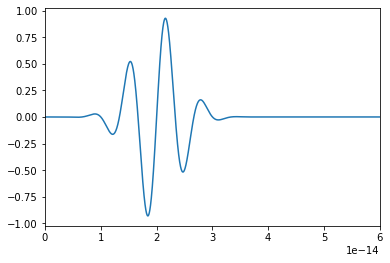

In [10]:
plt.figure()
plt.plot(t,y)
plt.xlim([0,6*tau])
plt.show()

## Definition of Fourier part

In [11]:
yf = fft.rfft(y)
xf = 2.*np.pi*fft.rfftfreq(len(t), d=TimeStep)
# xf = fft.fftshift(xf) #no effect in real space
photon_energy = hbar*xf/e #converting in eV

yplot = yf
# yplot = fft.fftshift(yf) #no effect in real space

print(np.shape(photon_energy))
print(np.shape(yplot))

(5001,)
(5001,)


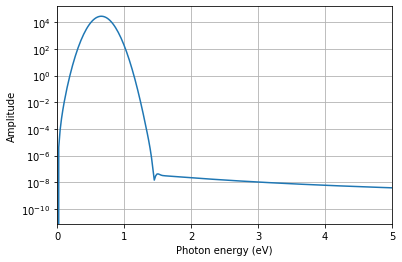

In [12]:
plt.figure()
# plt.semilogy(xf, 1.0/N * np.abs(yplot)) #amplitude
plt.semilogy(photon_energy, photon_energy**2 * np.abs(yplot)**2) #Larmor formula
# plt.xlabel("Frequency (Hz)")
plt.xlabel("Photon energy (eV)")
plt.ylabel("Amplitude")
plt.xlim(0,5)
plt.grid()
plt.show()

## Trying to increase size of the signal

In [13]:
print(np.shape(y))
print(np.shape(t))

(10000,)
(10000,)


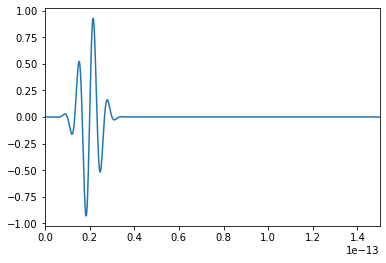

In [14]:
t2 = np.arange(tmin, 2*tmax, TimeStep)
y.resize(20_000,refcheck=False)

plt.figure()
plt.plot(t2,y)
plt.xlim([0,1.5e-13])
plt.show()

# Harmonic spectrum as function of angle of polarization
## Fetching runs computed with various angles of polarization

In [42]:
data=datafull
datatmp=data

## 1. Searching for runs that were prepared for various angles of polarization...
datatmp=datatmp[datatmp.PolarizationAngle!=0]
## 2. Filtering the non-zero CEP1
datatmp=datatmp[datatmp.CEP1==0]
## 3. Checking variety of wavelengtha and pulse durations
print("Wavelengths: ", set(datatmp.lambda1))
print("Pulse duration: ", set(datatmp.tau1))

Wavelengths:  {2.656e-06}
Pulse duration:  {1.3944999999999999e-14, 3e-14}


In [43]:
## 4. Since data are fully matching with case of M. Kozak, lets isolate by wavelength directly, keeping all orientation angles
datatmp=datafull
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.lambda1==2656e-9]
datatmp=datatmp[np.abs(datatmp.tau1 - 13.945e-15)/datatmp.tau1 < 0.01]
print("Fields: ", set(datatmp.Efield1))

Fields:  {10500000000.0, 3000000000.0}


In [44]:
datatmp

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2230,441932.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.000000,0.0,0.000003,...,0.0,78.535969,2.231728e+15,8.493052e+28,6.090377e+42,6.090392e+42,1.0,0.0,3266.25,1153.010893
2231,441931.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.0,0.477183,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2257,460313.0,20210604.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.000000,0.0,0.000003,...,0.0,78.535969,2.231728e+15,8.493052e+28,6.090377e+42,6.090392e+42,1.0,0.0,3266.25,1153.010893
2260,460293.0,20210531.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.0,0.477183,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2311,441962.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.0,0.000003,...,0.0,0.314102,-8.768611e+14,2.479285e+27,1.779908e+41,1.777902e+41,1.0,0.0,3266.25,1153.010893
2312,441963.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,0.0,0.000003,...,0.0,39.649807,-2.175106e+15,8.573558e+28,6.148288e+42,6.148123e+42,1.0,0.0,3266.25,1153.010893
2332,460354.0,20210612.0,24.0,0.434637,0.000003,1.394500e-14,1.050000e+10,0.785398,0.0,0.000003,...,0.0,39.649807,-2.175106e+15,8.573558e+28,6.148288e+42,6.148123e+42,1.0,0.0,3266.25,1153.010893
2337,460333.0,20210606.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.785398,0.0,0.000003,...,0.0,0.314102,-8.768611e+14,2.479285e+27,1.779908e+41,1.777902e+41,1.0,0.0,3266.25,1153.010893


We need more computations!! 

1. HHG spectrum convergence test: k=32, k=48
2. Run multiple orientations with converged k-grid. Where are multiple orientations I computed before? 
3. Run multiple CEP again with converged k-grid
4. Run real pulse shape with converged k-grid